# Two-colour metalens

Focus green and red light on one line with a metalens of silicon nitride ridges.

**Question.** A row of silicon nitride ridges on glass is lit from the glass by green
(532 nm) and red (633 nm) laser light at normal incidence, with the electric field along
the ridges (TE). Which ridge widths, one per cell across a 120 µm aperture, focus both
colours on the same line 300 µm behind the ridges?

Solving 401 ridges at once is out of reach. The **locally periodic approximation**
replaces each ridge by the infinite array of itself, which sends out one plane wave. One
cell solved for a range of widths gives the **cell response**, the transmission against
width. A tabulated cell at every position gives the **aperture field**, the angular
spectrum carries it to the focus, and gradients through the chain choose the widths:

ridge width $w_j$ → **cell response** $t(w_j)$ → **aperture field** → **propagation** to
the focus → focal intensity of each colour → **soft minimum** → optimizer.

The cell is a periodic cell with Floquet ports, as in {doc}`metagrating`; the helpers
live in {py:mod}`gfem.diffraction`.

**Assumptions.**

- A cylindrical lens: lines along $y$, one ridge per cell of pitch $a = 0.3$ µm and
  height 1.1 µm, widths 0.07 to 0.23 µm (aspect ratio up to 16, within what is reported
  for nitride metasurfaces). It focuses along $x$ only.
- Silicon nitride with the dispersive law of {py:func}`gfem.materials.silicon_nitride`;
  glass is silica at 633 nm, a constant, as a Floquet half-space needs; its 0.004 index
  difference between the colours is neglected. The air is lossless.
- The pitch is below $\lambda/n_\text{glass} = 0.364$ µm at 532 nm, so only the specular
  order propagates and four Floquet ports (TE and TM on each face) are complete.
- Second-order elements, 0.0375 µm cells across the ridge and 0.05 µm high.

**The physics.** An ideal lens at wavelength $\lambda$ has unit transmission and the phase

$$
\varphi(x) = \frac{2\pi}{\lambda}\left(\sqrt{x^2 + f^2} - f\right),
$$

for a field that propagates as $e^{-ik_z d}$: the extra path of a ray from $x$, compared
with the axis. A ridge adds a different phase to green and to red, which the optimization
below trades.

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from scipy.constants import c
from scipy.integrate import quad

import gfem
from gfem import diffraction

jax.config.update("jax_enable_x64", True)

um = 1e-6
LAMBDAS = np.array([532.0, 633.0]) * 1e-9  # green and red
FREQS = c / LAMBDAS  # Hz
PITCH, HEIGHT, W0 = 0.3, 1.1, 0.15  # um
W_LO, W_HI = 0.07, 0.23  # um, the widths the library covers
GLASS_DEPTH, AIR_GAP = 0.2, 0.25  # um, the glass and the air above the ridge's top

## The cell

The mesh is one period, 0.3 µm along $x$ and 0.16 µm along $y$, built at a ridge width of
$w_0 = 0.15$ µm: `"glass"` (0.2 µm), the `"ridge"` with `"air"` beside it (1.1 µm) and
`"air"` above (0.25 µm). Its surfaces are the open faces `"bottom"` and `"top"`, the
periodic pairs `"x_min"`, `"x_max"` and `"y_min"`, `"y_max"`, the ridge's walls
`"sidewall"`, and two planes that keep their place when the walls move: `"base"` and
`"ridge_top"`. The notebook reads it from {download}`data/metalens_cell.msh`. Before any
port is declared the cell lists the orders that propagate behind each face.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/metalens_cell.msh"), length_unit="um")
plain = gfem.Model(
    mesh,
    materials={
        "glass": gfem.materials.silica(frequency=FREQS[1]),
        "ridge": gfem.materials.silicon_nitride(),
        "air": gfem.Material(name="air"),
    },
    boundaries=[gfem.Periodic(("x_min", "x_max")), gfem.Periodic(("y_min", "y_max"))],
)
print("orders propagating in the glass:", plain.propagating_orders("bottom", FREQS))
print("orders propagating in the air:  ", plain.propagating_orders("top", FREQS))

orders propagating in the glass: ((0, 0),)
orders propagating in the air:   ((0, 0),)


Only the specular order $(0, 0)$ propagates, on both sides, at both colours.
{py:func}`gfem.diffraction.floquet_ports` declares a TE and a TM port for every order that
propagates at any of the frequencies. `offset` moves the reference planes to the surfaces
the light crosses, the glass surface (0.2 µm above the bottom face) and the ridge tops
(0.25 µm below the top face); the lens needs the phase at these planes.

In [3]:
cell = plain.replace(
    ports=[
        *diffraction.floquet_ports(plain, "bottom", FREQS, offset=GLASS_DEPTH * um),
        *diffraction.floquet_ports(plain, "top", FREQS, offset=AIR_GAP * um),
    ]
)
print([port.name for port in cell.ports])

['bottom (0, 0) TE', 'bottom (0, 0) TM', 'top (0, 0) TE', 'top (0, 0) TM']


One solve of the cell at $w_0$, both colours at once, exciting every port.
{py:func}`gfem.diffraction.power_balance` sums every Floquet row for the TE incidence; the
media are lossless, so the absorptance is the mesh's defect.
{py:func}`gfem.diffraction.jones` reads the $2 \times 2$ transmission block in (TM, TE):
its off-diagonal entries are the cross-polarization the lens neglects.

In [4]:
options = gfem.SolverOptions(order=2, linear_solver="direct")
tic = time.perf_counter()
solved = gfem.solve(cell, gfem.Driven(frequency=FREQS, excite=None), options=options)
print(f"one solve at both colours: {time.perf_counter() - tic:.1f} s")
balance = diffraction.power_balance(solved, "bottom", polarization="TE", model=cell)
jones = diffraction.jones(solved, "top", "bottom", model=cell)
t_te = np.asarray(jones.values[:, 1, 1])
balance_cell = float(np.max(np.abs(np.asarray(balance.absorptance))))
cross_polarization = float(np.max(np.abs(np.asarray(jones.values[:, 0, 1]))))
for i, name in enumerate(("532 nm", "633 nm")):
    print(
        f"{name}: R = {float(balance.reflectance[i]):.4f}, "
        f"T = {float(balance.transmittance[i]):.4f}, "
        f"A = {float(balance.absorptance[i]):+.1e}"
    )
t_tm = np.asarray(jones.values[:, 0, 0])
for pol, t in (("TE", t_te), ("TM", t_tm)):
    phase = np.degrees(np.angle(t)).round(1)
    print(f"t_{pol}: |t| = {np.abs(t).round(4)}, phase = {phase} deg")
print(f"largest cross-polarized entry: {cross_polarization:.1e}")
print(f"largest |A|: {balance_cell:.1e}")

one solve at both colours: 2.4 s


532 nm: R = 0.0971, T = 0.9029, A = +1.3e-05
633 nm: R = 0.0365, T = 0.9635, A = +6.4e-06
t_TE: |t| = [0.9502 0.9816], phase = [104.9  -3.1] deg
t_TM: |t| = [0.9687 0.9816], phase = [ -52.2 -173.2] deg
largest cross-polarized entry: 5.2e-04
largest |A|: 1.3e-05


At $w_0 = 0.15$ µm the ridge transmits 0.95 of the TE field at 532 nm and 0.98 at 633 nm,
and the TE and TM phases differ: the ridges are a form-birefringent wave plate, which is
why this lens is a TE lens. The absorptance is $1 \times 10^{-5}$ at worst and the
cross-polarized entries are at most $5 \times 10^{-4}$: TE stays TE.

**Mesh check.** The same cell at third order changes $t_\text{TE}$ by at most 0.0077
(`order3_change`, asserted below 0.02), the discretization error of the table and the limit
on the second digit of the efficiencies below.

In [5]:
tic = time.perf_counter()
third = gfem.solve(
    cell,
    gfem.Driven(frequency=FREQS, excite=None),
    options=gfem.SolverOptions(order=3, linear_solver="direct"),
)
t_third = np.asarray(
    diffraction.jones(third, "top", "bottom", model=cell).values[:, 1, 1]
)
order3_change = float(np.max(np.abs(t_third - t_te)))
print(
    f"order 3: {time.perf_counter() - tic:.0f} s, max |t3 - t2| = {order3_change:.1e}"
)

order 3: 7 s, max |t3 - t2| = 7.7e-03


## One mesh for every width

Meshing each width of the table would put a different discretization error in every
sample, which the interpolation cannot remove. Instead one mesh moves:
{py:func}`gfem.shape.boundary_morph` displaces the nodes of `"sidewall"` along their
normals (`grows="ridge"`), with `"base"` and `"ridge_top"` held, each wall by half the
widening: `morph(dw * um * 0.5)`. The widths must stay where
{py:func}`gfem.shape.quality` stays above a quarter of the imported mesh's: here 0.07 to
0.23 µm.

In [6]:
morph = gfem.shape.boundary_morph(cell, "sidewall", grows="ridge")
HALF = 0.5 * jnp.ones(morph.n_params)  # each wall moves half the widening
print("nodes the morph moves:", morph.n_params)


def make_cell(w, dw):
    # The cell with ridges w + dw um wide (w in um; dw a traced 0 of the derivative).
    return cell.replace(mesh=morph(((w - W0) + dw) * um * HALF))


q0 = np.asarray(gfem.shape.quality(cell.mesh))
ratio = {}
for w in np.linspace(W_LO, W_HI, 9):
    ratio[round(float(w), 4)] = float(
        np.min(np.asarray(gfem.shape.quality(make_cell(w, 0.0).mesh)) / q0)
    )
quality_ratio = min(ratio.values())
print(
    "worst element quality against the imported mesh, by width:",
    {k: round(v, 3) for k, v in ratio.items()},
)

nodes the morph moves: 92


worst element quality against the imported mesh, by width: {0.07: 0.324, 0.09: 0.476, 0.11: 0.647, 0.13: 0.828, 0.15: 1.0, 0.17: 0.83, 0.19: 0.651, 0.21: 0.481, 0.23: 0.33}


The worst element's quality against the imported mesh is 0.32 at both ends of the range
and falls towards 1 at $w_0$. The cell at three widths, the ridge in dark and the glass
and air around it light, on the plane $y = 0$:

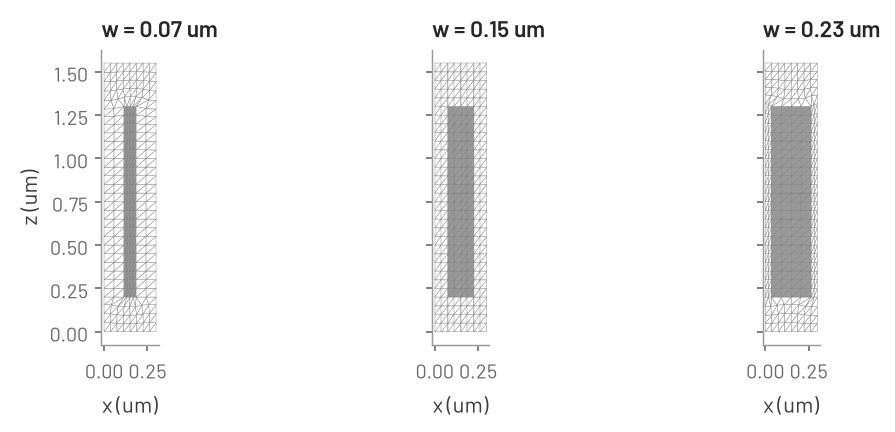

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(8, 3.0), sharey=True)
ridge_elements = np.asarray(cell.mesh.elements("ridge"))
for ax, w in zip(axes, (0.07, 0.15, 0.23), strict=True):
    m = make_cell(w, 0.0).mesh
    nodes = np.asarray(m.nodes) / um
    tets = np.asarray(m.tetrahedra)
    on_plane = np.isclose(nodes[:, 1], 0.0)
    ridge = np.zeros(len(tets), bool)
    ridge[ridge_elements] = True
    # the y = 0 plane's triangles: the tetrahedra's faces with three nodes there
    tris, in_ridge = [], []
    for tet, r in zip(tets, ridge, strict=True):
        flat = tet[on_plane[tet]]
        if len(flat) == 3:
            tris.append(flat)
            in_ridge.append(r)
    tris, in_ridge = np.array(tris), np.array(in_ridge)
    ax.tripcolor(
        nodes[:, 0],
        nodes[:, 2],
        tris,
        facecolors=np.where(in_ridge, 1.0, 0.0),
        cmap="gray_r",
        vmin=0,
        vmax=2.5,
        edgecolors="gray",
        linewidth=0.2,
    )
    ax.set_title(f"w = {w:.2f} um")
    ax.set_xlabel("x (um)")
    ax.set_aspect("equal")
axes[0].set_ylabel("z (um)")
fig.tight_layout();

## The cell response

{py:func}`gfem.diffraction.cell_response` takes a function `make_cell(w, dw)`, the
parameter samples and the frequencies, and solves the cell at each. `w` is a plain number,
`dw` a JAX scalar whose value is 0 and which moves the mesh, so the stored derivative
$\partial S/\partial w$ is exact for the discrete model; see
{doc}`../recipes/metasurface-from-cells`.

21 widths, denser where the phase turns fastest: $w = 0.07 + 0.16\,u^{1.6}$ µm for $u$ from
0 to 1.

In [8]:
widths = np.round(W_LO + (W_HI - W_LO) * np.linspace(0, 1, 21) ** 1.6, 6)  # um
print("widths:", widths)

widths: [0.07     0.071326 0.074019 0.077689 0.082183 0.087411 0.093308 0.099828
 0.106933 0.114592 0.12278  0.131475 0.140658 0.150312 0.160423 0.170976
 0.18196  0.193365 0.205179 0.217393 0.23    ]


In [9]:
tic = time.perf_counter()
response = diffraction.cell_response(
    make_cell,
    widths,
    frequency=FREQS,
    excite=["bottom (0, 0) TE"],
    options=options,
)
t_build = time.perf_counter() - tic
print(f"{len(widths)} samples at 2 colours: {t_build:.0f} s")
print(response.ports)
print(response.offsets)

21 samples at 2 colours: 105 s
('bottom (0, 0) TE', 'bottom (0, 0) TM', 'top (0, 0) TE', 'top (0, 0) TM')
{'bottom (0, 0) TE': 2e-07, 'bottom (0, 0) TM': 2e-07, 'top (0, 0) TE': 2.5e-07, 'top (0, 0) TM': 2.5e-07}


The response is the one slow step of the page (its time is printed above). It holds S and
$\partial S/\partial w$ at each sample, and between samples a piecewise cubic Hermite
interpolant of the real and imaginary parts, a pure JAX function of $w$ that
differentiates, `jit`s and `vmap`s.

**Check: the stored derivative.** At one sample the stored $\partial t/\partial w$ against
a central difference of two solves of the morphed cell, a step of $10^{-4}$ µm either side:

In [10]:
OUT_TE = response.ports.index("top (0, 0) TE")


def te(w):
    # Transmission of TE from the glass at width w, both colours: shape (2,).
    return response(w).values[:, OUT_TE, 0]


# the stored derivative against a central difference of two solves, at one sample
k, step = 4, 1e-4  # sample 4, step in um
w_k = float(widths[k])


def solved_te(w):
    res = gfem.solve(
        make_cell(w, 0.0),
        gfem.Driven(frequency=FREQS, excite=["bottom (0, 0) TE"]),
        options=options,
    )
    return np.asarray(res.s["top (0, 0) TE", "bottom (0, 0) TE"])


central = (solved_te(w_k + step) - solved_te(w_k - step)) / (2 * step)
stored = np.asarray(response.derivative[k, :, OUT_TE, 0])
derivative_error = float(np.max(np.abs(stored - central) / np.abs(central)))
print(f"width {w_k:.4f} um: stored dt/dw = {stored}, central difference = {central}")
print(f"relative difference: {derivative_error:.1e}")

width 0.0822 um: stored dt/dw = [-65.80310309-24.53608506j  22.50621594+49.25205338j], central difference = [-65.8021905 -24.53622378j  22.50597237+49.25196249j]
relative difference: 1.3e-05


The two agree to $1.3 \times 10^{-5}$ in relative terms (`derivative_error`, asserted
below $10^{-4}$): the finite difference's own truncation and the morph's. The derivative is
the model's, not an approximation to it.

**Check: the interpolation.** Between samples the response is the Hermite interpolant,
whose error falls as the fourth power of the spacing. The four midpoints of the narrowest
intervals, solved directly and compared with `response(w)`:

In [11]:
mid = 0.5 * (widths[:4] + widths[1:5])  # the midpoints of the four narrowest intervals
direct = np.array([solved_te(w) for w in mid])  # (4, 2)
interpolated = np.array([np.asarray(te(w)) for w in mid])
hermite_error = float(np.max(np.abs(interpolated - direct)))
print("held-out widths:", mid.round(4))
print("max |response(w) - solve(w)| =", f"{hermite_error:.1e}")
print("by width and colour:", np.abs(interpolated - direct).round(7))

held-out widths: [0.0707 0.0727 0.0759 0.0799]
max |response(w) - solve(w)| = 8.6e-05
by width and colour: [[4.00e-07 2.70e-06]
 [9.00e-06 3.30e-06]
 [3.69e-05 6.90e-06]
 [8.59e-05 1.70e-05]]


The largest difference over both colours is $8.6 \times 10^{-5}$ (`hermite_error`,
asserted below $10^{-3}$), at 532 nm and 0.0799 µm (633 nm: $1.7 \times 10^{-5}$), where
the samples are 0.0045 µm apart. The table, samples as dots and the interpolant between:

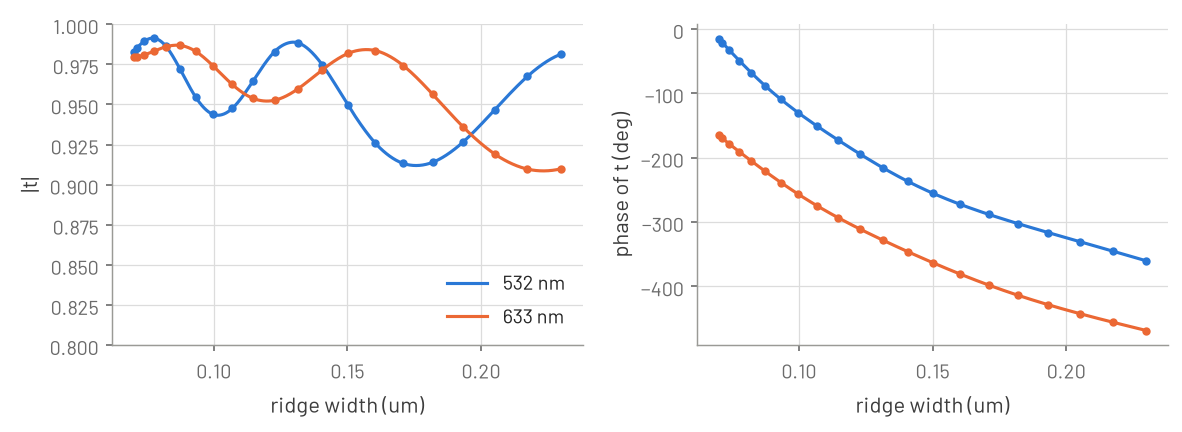

In [12]:
fine = np.linspace(W_LO, W_HI, 801)
t_fine = np.asarray(jax.vmap(te)(jnp.asarray(fine)))  # (801, 2)
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)
for i, (name, colour) in enumerate((("532 nm", "C0"), ("633 nm", "C1"))):
    sample = np.asarray(response.values[:, :, OUT_TE, 0][:, i])
    axes[0].plot(fine, np.abs(t_fine[:, i]), color=colour, ls="-", label=name)
    axes[0].plot(widths, np.abs(sample), color=colour, ls="none", marker="o", ms=3)
    axes[1].plot(
        fine,
        np.degrees(np.unwrap(np.angle(t_fine[:, i]))),
        color=colour,
        ls="-",
        label=name,
    )
    axes[1].plot(
        widths,
        np.degrees(np.unwrap(np.angle(sample))),
        color=colour,
        ls="none",
        marker="o",
        ms=3,
    )
axes[0].set_ylabel("|t|")
axes[0].set_ylim(0.8, 1.0)
axes[1].set_ylabel("phase of t (deg)")
for ax in axes:
    ax.set_xlabel("ridge width (um)")
axes[0].legend(loc="lower right")
fig.tight_layout();

In [13]:
span = [np.ptp(np.degrees(np.unwrap(np.angle(t_fine[:, i])))) for i in range(2)]
print(
    "phase span over the widths (deg):",
    np.round(span, 0),
    " min |t|:",
    np.abs(t_fine).min(0).round(3),
)

phase span over the widths (deg): [345. 303.]  min |t|: [0.912 0.909]


The phase of $t$ spans 345° at 532 nm and 303° at 633 nm across the widths, and $|t|$
stays above 0.91: nearly a full $2\pi$ at nearly full transmission, what a lens needs.
Narrow ridges change the phase fastest, about 3000° per µm at $w = 0.07$ µm.

## The ideal lens and the classic design

Aperture: 401 cells, $D = 401 a = 120.3$ µm, focal length $f = 300$ µm, numerical aperture
0.196, cell $j$ at $x_j = (j - 200)\,a$. An ideal lens has $|t| = 1$ and the phase
$\varphi$ above;
{py:class}`gfem.diffraction.ApertureField` takes the samples directly and
{py:func}`gfem.diffraction.propagate` carries them to $z = f$, giving the focal intensity
$I_\text{ideal}$ that every design is measured against.

**Check: the focus of an ideal lens.** In the stationary-phase limit the focal intensity of
a cylindrical lens is

$$
I_\text{ideal} = \frac1\lambda \left(\int_{-D/2}^{D/2} \frac{f}{(x^2 + f^2)^{3/4}}\,dx\right)^2,
$$

which does not use the angular spectrum or the sampling. The two:

In [14]:
N, FOCAL = 401, 300 * um
X = (np.arange(N) - (N - 1) / 2) * PITCH * um  # m, a cell at the centre
CENTRE = N // 2
K0 = 2 * np.pi * FREQS / c
LENS_PHASE = K0[:, None] * (np.sqrt(X**2 + FOCAL**2) - FOCAL)  # (2, N)
t_ideal = jnp.asarray(np.exp(1j * LENS_PHASE))
ideal = diffraction.ApertureField(
    jnp.stack([jnp.zeros_like(t_ideal), t_ideal], axis=1), FREQS, X
)
I_ideal = np.asarray(diffraction.propagate(ideal, FOCAL).intensity[:, CENTRE])
half = N * PITCH / 2  # um
integral = quad(lambda s: 300.0 * (s**2 + 300.0**2) ** -0.75, -half, half)[
    0
]  # um^(1/2)
I_stationary = integral**2 / (LAMBDAS / um)
ideal_focus = float(np.max(np.abs(I_ideal / I_stationary - 1)))
print(
    "ideal lens focal intensity:",
    I_ideal.round(2),
    " stationary phase:",
    I_stationary.round(2),
)
print(f"relative difference: {ideal_focus:.1e}")

ideal lens focal intensity: [88.84 74.78]  stationary phase: [88.9  74.72]
relative difference: 7.9e-04


They agree to $7.9 \times 10^{-4}$ (`ideal_focus`, asserted below $2 \times 10^{-3}$): the
propagation, the sampling and the sign of the phase are right.

**The classic design: phase matching.** For each cell, choose the width whose transmission
phase at 633 nm is closest to the ideal lens's, up to one global phase offset (72 tried,
the best kept). The focal intensity of both colours, relative to the ideal lens:

In [15]:
def field_of(w):
    return diffraction.aperture_field(response, w, "top", "bottom", polarization="TE")


def relative_focus(w, distance=FOCAL):
    # Focal intensity at the axis against the ideal lens, both colours.
    return diffraction.propagate(field_of(w), distance).intensity[:, CENTRE] / I_ideal


t_unit = t_fine[:, 1] / np.abs(t_fine[:, 1])  # the 633 nm phasor along the widths
best = (-1.0, None)
for offset in np.linspace(0, 2 * np.pi, 72, endpoint=False):
    target = np.exp(1j * (LENS_PHASE[1] + offset))
    w = fine[np.argmin(np.abs(t_unit[None, :] - target[:, None]), axis=1)]
    score = float(relative_focus(jnp.asarray(w))[1])
    if score > best[0]:
        best = (score, w)
w_matched = best[1]
matched = np.asarray(relative_focus(jnp.asarray(w_matched)))
print(
    "phase matched at 633 nm, focal intensity against the ideal lens:", matched.round(3)
)

phase matched at 633 nm, focal intensity against the ideal lens: [0.055 0.92 ]


`matched` is the focal intensity against the ideal lens: 0.055 at 532 nm and 0.920 at 633
nm. Red is nearly ideal and green is almost not focused: the widths were chosen for red. A
scan along the axis shows where the green goes.

In [16]:
Z = np.linspace(100, 600, 101) * um
field_m = field_of(jnp.asarray(w_matched))
axial_m = (
    np.array(
        [np.asarray(diffraction.propagate(field_m, z).intensity[:, CENTRE]) for z in Z]
    )
    / I_ideal
)
green_peak = Z[np.argmax(axial_m[:, 0])] / um
red_peak = Z[np.argmax(axial_m[:, 1])] / um
shift = 300 * LAMBDAS[1] / LAMBDAS[0]
green_focus = abs(green_peak / shift - 1)
print(f"axial peak: green {green_peak:.0f} um, red {red_peak:.0f} um")
print(f"f * 633 / 532 = {shift:.1f} um; green_focus = {green_focus:.3f}")
print("height of the peaks against the ideal lens at f:", axial_m.max(0).round(3))

axial peak: green 355 um, red 300 um
f * 633 / 532 = 357.0 um; green_focus = 0.005
height of the peaks against the ideal lens at f: [0.737 0.92 ]


The red focus is at 300 µm, as designed; the green peaks at 355 µm, at 0.737 of the ideal
focal intensity: the light is there, at the wrong distance. A diffractive focus scales as
$1/\lambda$, so green focuses at $f\lambda_\text{red}/\lambda_\text{green} = 357.0$ µm,
and the matched lens's green peak is within 0.005 of it (`green_focus`, asserted below
0.03).

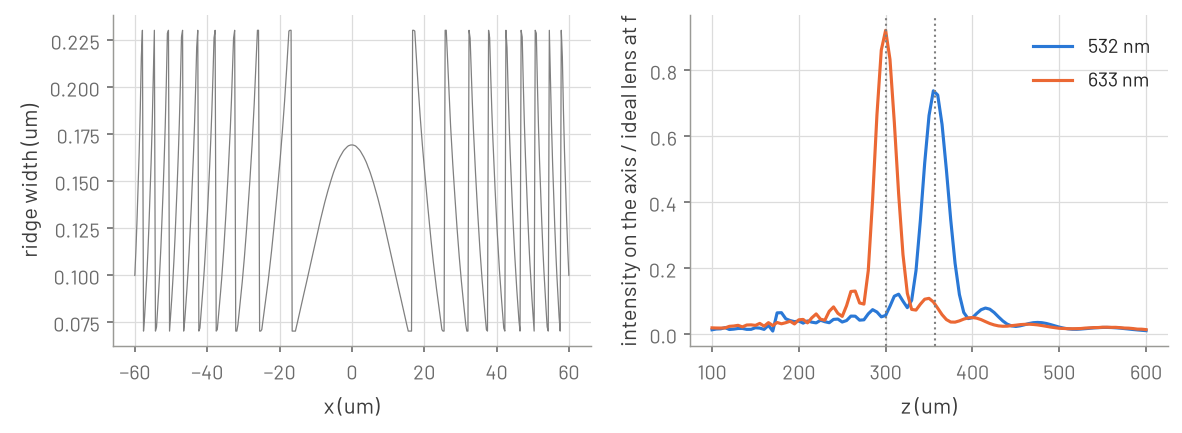

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(X / um, w_matched, color="gray", lw=0.6)
axes[0].set_xlabel("x (um)")
axes[0].set_ylabel("ridge width (um)")
for i, (name, colour) in enumerate((("532 nm", "C0"), ("633 nm", "C1"))):
    axes[1].plot(Z / um, axial_m[:, i], color=colour, ls="-", label=name)
axes[1].axvline(300, color="gray", ls=":", lw=1)
axes[1].axvline(shift, color="gray", ls=":", lw=1)
axes[1].set_xlabel("z (um)")
axes[1].set_ylabel("intensity on the axis / ideal lens at f")
axes[1].legend(loc="upper right")
fig.tight_layout();

## Optimize both colours

The widths are free, one per cell, as $w = w_\text{lo} + (w_\text{hi} - w_\text{lo})\,\sigma(z)$
with $z$ unbounded, so that the optimizer cannot leave the table's range (the response
returns NaN outside it). The objective is the **soft minimum** of the two relative focal
intensities $r_1, r_2$,

$$
\operatorname{softmin}(r) = -\tau \log \sum_i e^{-r_i/\tau}, \qquad \tau = 0.05,
$$

which rewards raising the weaker colour. The gradient runs through the sigmoid, the
interpolation, the aperture field and the propagation in one `jax.value_and_grad`.

**Check: the gradient.** At the phase-matched design, along a random unit direction of the
401 variables, against a central difference of the loss with a step of $10^{-5}$:

In [18]:
TAU = 0.05


def to_width(z):
    return W_LO + (W_HI - W_LO) * jax.nn.sigmoid(z)


def from_width(w):
    s = np.clip((w - W_LO) / (W_HI - W_LO), 1e-4, 1 - 1e-4)
    return np.log(s / (1 - s))


def loss(z):
    r = relative_focus(to_width(z))
    return TAU * jax.nn.logsumexp(
        -r / TAU
    ), r  # minus the soft minimum; both intensities


value_and_grad = jax.jit(jax.value_and_grad(loss, has_aux=True))

z = jnp.asarray(from_width(w_matched))
direction = np.random.default_rng(0).standard_normal(N)
direction /= np.linalg.norm(direction)
(_, _), g = value_and_grad(z)
along = float(jnp.dot(g, direction))
step = 1e-5
difference = (
    float(loss(z + step * direction)[0]) - float(loss(z - step * direction)[0])
) / (2 * step)
fd_error = abs(along - difference) / abs(difference)
print(f"gradient along a random direction {along:+.9e}")
print(f"central difference (step 1e-5)    {difference:+.9e}")
print(f"relative difference: {fd_error:.1e}")

gradient along a random direction -7.459771210e-04
central difference (step 1e-5)    -7.459771210e-04
relative difference: 9.1e-11


They agree to $3.3 \times 10^{-9}$ in relative terms (`fd_error`, asserted below $10^{-6}$).

[optax](https://optax.readthedocs.io)'s Adam, step 0.05, 400 iterations from the phase-matched
design, one loss and gradient each:

In [19]:
optimizer = optax.adam(0.05)
state = optimizer.init(z)
history = []
tic = time.perf_counter()
for _ in range(400):
    (_, r), g = value_and_grad(z)
    updates, state = optimizer.update(g, state)
    z = optax.apply_updates(z, updates)
    history.append(np.asarray(r))
history = np.array(history)
w_opt = np.asarray(to_width(z))
optimized = np.asarray(relative_focus(jnp.asarray(w_opt)))
print(f"400 steps in {time.perf_counter() - tic:.1f} s")
print("start (matched):", matched.round(3), " optimized:", optimized.round(3))

400 steps in 1.4 s
start (matched): [0.055 0.92 ]  optimized: [0.499 0.507]


`optimized` is the focal intensity against the ideal lens: 0.499 at 532 nm and 0.507 at 633
nm, from 0.055 and 0.920. Red falls to about 0.51 to raise green to about 0.50: the soft
minimum's trade. Maximizing the mean instead is the wrong objective, as the next cell shows.

In [20]:
def mean_loss(z):
    return -jnp.mean(relative_focus(to_width(z)))


mean_grad = jax.jit(jax.value_and_grad(mean_loss))
zm = jnp.asarray(from_width(w_matched))
mean_state = optimizer.init(zm)
for _ in range(400):
    _, g = mean_grad(zm)
    updates, mean_state = optimizer.update(g, mean_state)
    zm = optax.apply_updates(zm, updates)
by_mean = np.asarray(relative_focus(to_width(zm)))
print("maximizing the mean instead:", by_mean.round(3))

maximizing the mean instead: [0.234 0.795]


The mean keeps red (0.795) and gives up on green (0.234): nothing in it penalizes the weaker
colour. The soft minimum asks for both.

The axial scan of the optimized lens: where do its foci sit?

In [21]:
field_o = field_of(jnp.asarray(w_opt))
axial_o = (
    np.array(
        [
            np.asarray(diffraction.propagate(field_o, z_).intensity[:, CENTRE])
            for z_ in Z
        ]
    )
    / I_ideal
)
peaks_o = Z[np.argmax(axial_o, axis=0)] / um
print("optimized lens axial peaks (um):", peaks_o, " heights", axial_o.max(0).round(3))
second = {
    "green at 355 um": axial_o[np.argmin(abs(Z - 355 * um)), 0],
    "red at 250 um": axial_o[np.argmin(abs(Z - 250 * um)), 1],
}
print("second foci:", {k: round(float(v), 3) for k, v in second.items()})
centre = slice(CENTRE - 1, CENTRE + 2)
print(
    "widths on the axis, matched and optimized (um):",
    w_matched[centre].round(3),
    w_opt[centre].round(3),
)

optimized lens axial peaks (um): [300. 295.]  heights [0.499 0.513]
second foci: {'green at 355 um': 0.371, 'red at 250 um': 0.455}
widths on the axis, matched and optimized (um): [0.169 0.169 0.169] [0.188 0.189 0.188]


Left, the relative focal intensity of each colour over the 400 iterations; right, the
widths of the two designs. The phase-matched widths are a sawtooth that follows the lens
phase, wrapping every $2\pi$; the 303° of the table at 633 nm leave a gap near
$|x| = 17$ µm. The optimized widths follow it, shifted: wider on the axis (0.189 µm
against 0.169 µm).

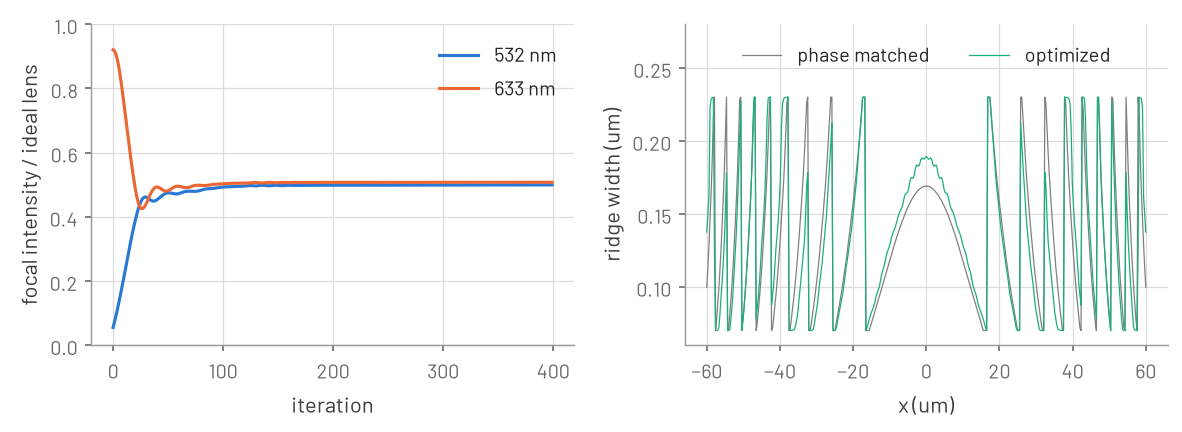

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for i, (name, colour) in enumerate((("532 nm", "C0"), ("633 nm", "C1"))):
    axes[0].plot(history[:, i], color=colour, ls="-", label=name)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("focal intensity / ideal lens")
axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper right")
axes[1].plot(X / um, w_matched, color="gray", lw=0.6, label="phase matched")
axes[1].plot(X / um, w_opt, color="C2", ls="-", lw=0.6, label="optimized")
axes[1].set_xlabel("x (um)")
axes[1].set_ylabel("ridge width (um)")
axes[1].legend(loc="upper center", ncol=2)
axes[1].set_ylim(0.06, 0.28)
fig.tight_layout();

Left, the intensity at $z = f$ near the focus, normalized by the ideal peak, phase matched
(dashed) and optimized (solid); right, the axial intensity. Green focuses at 300 µm and red
at 295 µm (the scan's grid is 5 µm), at 0.499 and 0.513 of the ideal intensity. The other
foci remain, with 0.371 at 355 µm in green and 0.455 at 250 µm in red; a term that
penalizes light elsewhere on the axis would be the next objective.

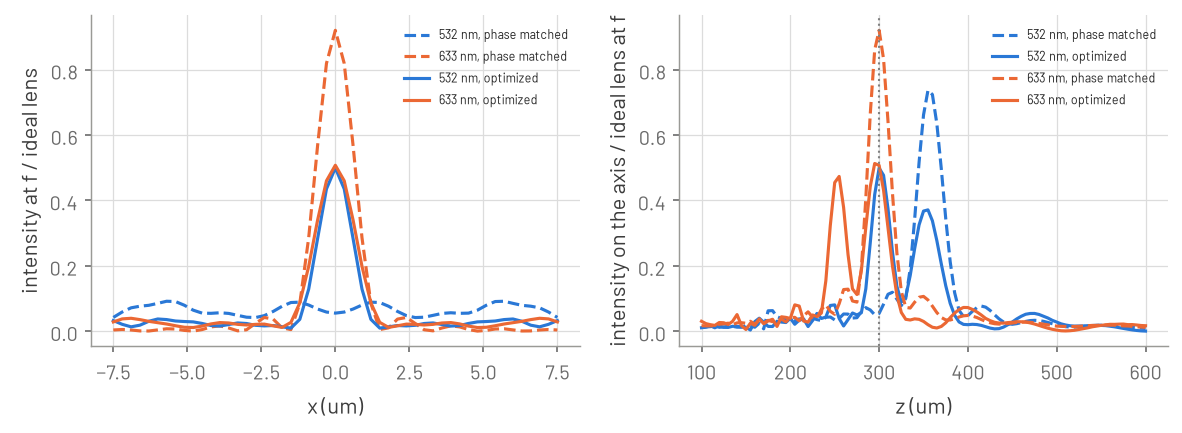

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
near = slice(CENTRE - 25, CENTRE + 26)
for field, style, label in (
    (field_m, "--", "phase matched"),
    (field_o, "-", "optimized"),
):
    at_f = np.asarray(diffraction.propagate(field, FOCAL).intensity) / I_ideal[:, None]
    for i, colour in enumerate(("C0", "C1")):
        axes[0].plot(
            X[near] / um,
            at_f[i, near],
            color=colour,
            ls=style,
            label=f"{('532', '633')[i]} nm, {label}",
        )
axes[0].set_xlabel("x (um)")
axes[0].set_ylabel("intensity at f / ideal lens")
axes[0].legend(fontsize=6)
for i, (name, colour) in enumerate((("532 nm", "C0"), ("633 nm", "C1"))):
    axes[1].plot(
        Z / um, axial_m[:, i], color=colour, ls="--", label=f"{name}, phase matched"
    )
    axes[1].plot(
        Z / um, axial_o[:, i], color=colour, ls="-", label=f"{name}, optimized"
    )
axes[1].axvline(300, color="gray", ls=":", lw=1)
axes[1].set_xlabel("z (um)")
axes[1].set_ylabel("intensity on the axis / ideal lens at f")
axes[1].legend(fontsize=6)
fig.tight_layout();

## How far to trust the approximation

The optimizer may use any width in any cell, and the approximation assumes each cell sees
neighbours like itself. The phase step between neighbours measures how far the design is
from that:

In [24]:
def steps(w):
    t = np.asarray(jax.vmap(te)(jnp.asarray(w)))
    return np.degrees(np.abs(np.angle(t[1:] * np.conj(t[:-1]))))  # (N - 1, 2)


for name, w in (("phase matched", w_matched), ("optimized", w_opt)):
    s = steps(w)
    print(
        name,
        "max step (deg):",
        s.max(0).round(0),
        " fraction above 60 deg:",
        (s > 60).mean(0).round(3),
        " median:",
        np.median(s, axis=0).round(0),
    )

phase matched max step (deg): [41. 57.]  fraction above 60 deg: [0. 0.]  median: [15. 15.]
optimized max step (deg): [175. 153.]  fraction above 60 deg: [0.03 0.04]  median: [14. 13.]


The phase-matched lens steps at most 41° (532 nm) and 57° (633 nm) between neighbours,
near the edge of the regime where the approximation's error stays at 0.01 to 0.02 in
amplitude (up to about 40°). The optimized lens has a median step of
13° to 14°, but 3 % of its pairs at 532 nm and 4 % at 633 nm step by more than 60°, up to
175° and 153°: abrupt steps focus better where a neighbour does not disturb its neighbour.

**A full solve of a deflector.** Ten ridges side by side, widths following a phase ramp of
36° per cell at 633 nm ($2\pi$ over the ten), which deflects light into the +1 order at
12.2°: the cell above ten times, {download}`data/metalens_supercell.msh`, 3 µm wide with
29 760 tetrahedra, ridges at $w_0$.

In [25]:
NS = 10
mesh_s = gfem.Mesh.from_gmsh(Path("data/metalens_supercell.msh"), length_unit="um")
plain_s = plain.replace(mesh=mesh_s)
cell_s = plain_s.replace(
    ports=[
        *diffraction.floquet_ports(
            plain_s, "bottom", FREQS[1], offset=GLASS_DEPTH * um
        ),
        *diffraction.floquet_ports(plain_s, "top", FREQS[1], offset=AIR_GAP * um),
    ]
)
print(
    len(cell_s.ports),
    "ports; orders in the air:",
    [p.order[0] for p in cell_s.ports if p.surface == "top" and p.polarization == "TE"],
)

44 ports; orders in the air: [0, -1, 1, -2, 2, -3, 3, -4, 4]


In [26]:
best = (np.inf, None)
for offset in np.linspace(0, 2 * np.pi, 72, endpoint=False):
    target = np.exp(1j * (offset - 2 * np.pi * np.arange(NS) / NS))  # 36 deg per cell
    pick = np.argmin(np.abs(t_unit[None, :] - target[:, None]), axis=1)
    error = np.abs(np.angle(t_unit[pick] * np.conj(target))).max()
    if error < best[0]:
        best = (error, fine[pick])
w_ramp = best[1]
print(
    "ramp widths (um):",
    w_ramp.round(3),
    " largest phase error:",
    np.degrees(best[0]).round(1),
    "deg",
)

ramp widths (um): [0.07  0.078 0.089 0.102 0.117 0.135 0.154 0.177 0.206 0.23 ]  largest phase error: 10.5 deg


The widths follow the phase ramp to within 11° (the table is only so dense in phase).

In [27]:
morph_s = gfem.shape.boundary_morph(cell_s, "sidewall", grows="ridge")
x_nodes = np.asarray(morph_s.points) / um
ridge_of = np.minimum((x_nodes[:, 0] // PITCH).astype(int), NS - 1)
super_cell = cell_s.replace(mesh=morph_s(jnp.asarray((w_ramp[ridge_of] - W0) / 2 * um)))
tic = time.perf_counter()
super_result = gfem.solve(
    super_cell,
    gfem.Driven(frequency=FREQS[1], excite=["bottom (0, 0) TE"]),
    options=options,
)
print(f"{len(mesh_s.tetrahedra)} tetrahedra, solve: {time.perf_counter() - tic:.0f} s")
super_balance = diffraction.power_balance(
    super_result, "bottom", polarization="TE", model=super_cell
)
supercell_balance = float(np.abs(np.asarray(super_balance.absorptance)).max())
print(f"largest |A|: {supercell_balance:.1e}")

29760 tetrahedra, solve: 54 s


largest |A|: 1.0e-05


One boundary morph moves every ridge at once. One driven solve at 633 nm excites the TE
wave from the glass: the page's second slow step, and the one that needs the most memory.

The power balance of the supercell closes: `supercell_balance`, the absorptance, is
$1 \times 10^{-5}$ (asserted below $10^{-4}$).

In [28]:
L = NS * PITCH * um
x_j = (np.arange(NS) + 0.5) * PITCH * um
t_ramp = np.asarray(jax.vmap(te)(jnp.asarray(w_ramp)))[:, 1]  # 633 nm
orders = range(-4, 5)
eta_fem, eta_lpa = {}, {}
for m in orders:
    s_m = complex(np.asarray(super_result.s[f"top ({m}, 0) TE", "bottom (0, 0) TE"])[0])
    sin_theta = m * LAMBDAS[1] / L
    c_m = np.mean(t_ramp * np.exp(2j * np.pi * m * x_j / L))
    eta_fem[m] = abs(s_m) ** 2
    eta_lpa[m] = np.sqrt(1 - sin_theta**2) * abs(c_m) ** 2
for m in orders:
    print(f"order {m:+d}: FEM {eta_fem[m]:.4f}   LPA {eta_lpa[m]:.4f}")
fem_deflected, lpa_deflected = eta_fem[1], eta_lpa[1]
deflected = abs(fem_deflected - lpa_deflected)

order -4: FEM 0.0028   LPA 0.0006
order -3: FEM 0.0062   LPA 0.0008
order -2: FEM 0.0064   LPA 0.0006
order -1: FEM 0.0047   LPA 0.0009
order +0: FEM 0.0046   LPA 0.0005
order +1: FEM 0.8696   LPA 0.8973
order +2: FEM 0.0050   LPA 0.0000
order +3: FEM 0.0026   LPA 0.0002
order +4: FEM 0.0018   LPA 0.0005


The aperture field's prediction for the same ten widths is the Fourier series of the
transmissions: the order $m$ carries $\sqrt{\cos\theta_m}\,c_m$ with
$c_m = \frac1N \sum_j t_j\,e^{2\pi i m x_j/L}$, an efficiency $\cos\theta_m\,|c_m|^2$. The
two, order by order:

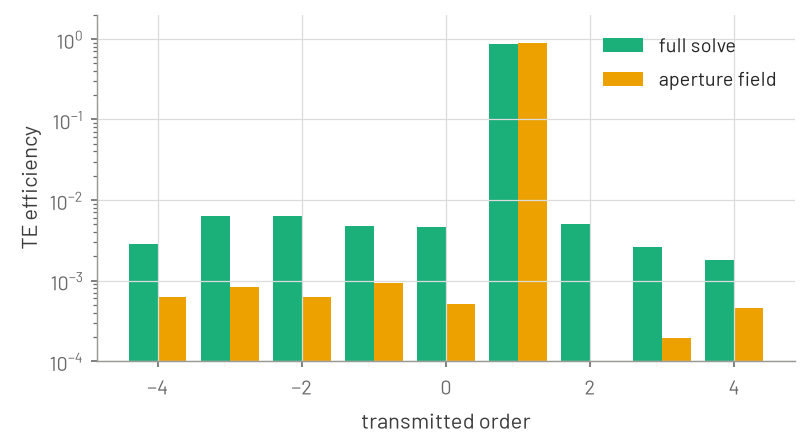

In [29]:
fig, ax = plt.subplots(figsize=(6, 3))
ms = np.array(list(orders))
ax.bar(
    ms - 0.2, [eta_fem[m] for m in ms], 0.4, color="C2", label="full solve", bottom=0
)
ax.bar(ms + 0.2, [eta_lpa[m] for m in ms], 0.4, color="C3", label="aperture field")
ax.set_yscale("log")
ax.set_ylim(1e-4, 2)
ax.set_xlabel("transmitted order")
ax.set_ylabel("TE efficiency")
ax.legend(loc="upper right");

The deflected +1 order carries 0.870 of the incident power in the full solve and 0.897 in
the approximation (`deflected`, asserted within 0.05): the approximation overestimates the
beam by 0.027, and each stray order carries 0.002 to 0.006 in the full solve and under
0.001 in the approximation. It sees none of the scattering between abrupt neighbours, so
its focal intensities are optimistic.

## Checks

| check | value | asserted |
| --- | --- | --- |
| cell power balance; cross-polarized entries | $1 \times 10^{-5}$; $5 \times 10^{-4}$ | below $10^{-4}$; $2 \times 10^{-3}$ |
| third order against second | 0.0077 | below 0.02 |
| stored derivative; interpolation | $1.3 \times 10^{-5}$; $8.6 \times 10^{-5}$ | below $10^{-4}$; $10^{-3}$ |
| ideal lens against closed form | $7.9 \times 10^{-4}$ | below $2 \times 10^{-3}$ |
| phase-matched lens, 532 and 633 nm | 0.055 and 0.920 | to 0.01 |
| its green focus against $f\lambda_\text{red}/\lambda_\text{green}$ | 0.005 | within 0.03 |
| optimized lens, 532 and 633 nm | 0.499 and 0.507 | at least 0.45; 0.50 and 0.51, to 0.03 |
| gradient against a difference | $3.3 \times 10^{-9}$ | below $10^{-6}$ |
| supercell power balance | $1 \times 10^{-5}$ | below $10^{-4}$ |
| deflected order, full solve; approximation | 0.870; 0.897 | to 0.01; within 0.05 |

## Limits

- **Neighbour coupling.** The approximation neglects it. The deflector is 0.027 lower in
  its +1 order than the approximation says, with stray orders 3.6 to 13 times stronger, at
  only 36° per cell; the optimized lens has steps up to 175°. Solve a supercell of a
  design's cells before building it.
- **One parameter, normal incidence, TE.** TM light sees the ridges as a different wave
  plate.
- **Two colours, not a band.** A colour between 532 and 633 nm is not optimized or focused.
- **Observation grid and mesh.** One sample per 0.3 µm against a focal spot a few cells
  wide: read the peak, not the profile. The second digit of every efficiency is good to
  about 0.01 at 532 nm.
- **Fabrication.** The table does not know sidewall angle or roughness.

## Next

- {doc}`../recipes/metasurface-from-cells`: the table, the aperture field and the
  objectives (Strehl ratio, deflection efficiency), step by step.
- {doc}`../recipes/diffraction-efficiency`: order efficiencies, Jones and Mueller matrices.
- {doc}`../recipes/emissivity`: the same Floquet cell as a thermal emitter.
- {doc}`metagrating`: a grating designed by topology optimization.
- {doc}`../recipes/shape-gradient`: the gradient of a solve with respect to the cell's shape.

In [30]:
np.testing.assert_array_less(balance_cell, 1e-4)
np.testing.assert_array_less(cross_polarization, 2e-3)
np.testing.assert_array_less(order3_change, 0.02)
np.testing.assert_array_less(derivative_error, 1e-4)
np.testing.assert_array_less(hermite_error, 1e-3)
np.testing.assert_array_less(ideal_focus, 2e-3)
np.testing.assert_allclose(matched, [0.055, 0.920], atol=0.01)
np.testing.assert_array_less(green_focus, 0.03)
np.testing.assert_array_less(0.45, optimized)
np.testing.assert_allclose(optimized, [0.50, 0.51], atol=0.03)
np.testing.assert_array_less(fd_error, 1e-6)
np.testing.assert_array_less(supercell_balance, 1e-4)
np.testing.assert_allclose([fem_deflected, lpa_deflected], [0.870, 0.897], atol=0.01)
np.testing.assert_array_less(deflected, 0.05)